# 03 - Açıklanabilirlik (SHAP)
"Model *neden* bu kararı verdi?" sorusu. Havacılıkta bir modelin sonucuna göre yatırım
kararı alınacaksa (ör. Wi-Fi'ye mi koltuğa mı yatırım yapalım) bu soru kritik.

Üç önem ölçüsü karşılaştırılır: **Impurity (Gini)**, **Permutation** ve **SHAP**.
*Önce 02 numaralı defteri çalıştırın (kaydedilen modeli kullanır).*

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src import config as C
from src import data_loader
from src import explainability as ex
from src import visualization as viz
from src.preprocessing import split_xy

viz.set_style()
pd.set_option("display.max_columns", 30)

In [2]:
train, test = data_loader.load_data()
X_test, y_test = split_xy(test)
rf = joblib.load(C.MODEL_DIR / "random_forest.joblib")

## 1. Impurity vs Permutation önemi
Gini önemi sayısal ve çok değerli özellikleri kayırabilir; permutation önemi gerçek test başarısına etkisini ölçer.

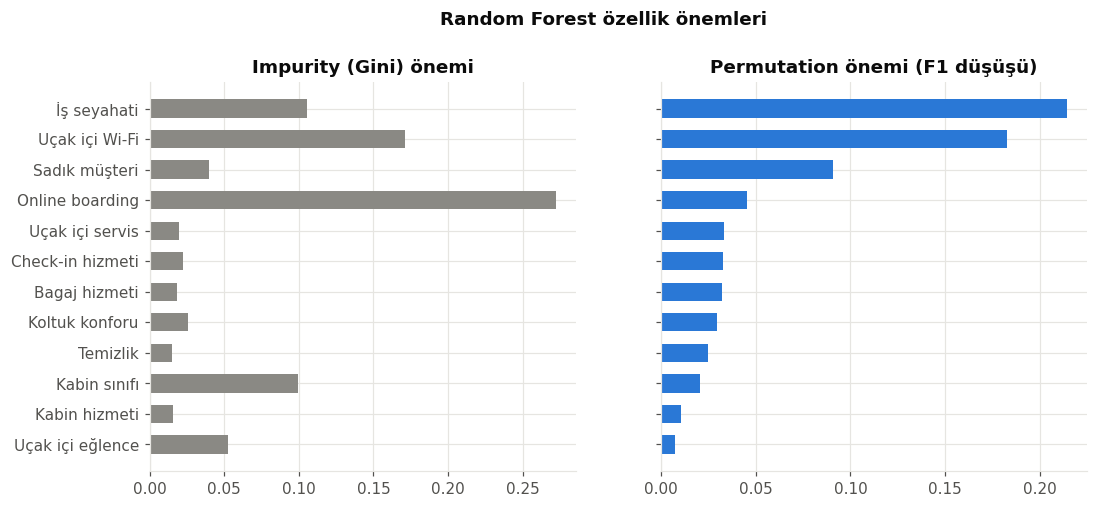

,feature,impurity,permutation
0,type_of_travel,0.1058,0.2144
1,inflight_wifi,0.1712,0.1826
2,customer_type,0.0399,0.0909
3,online_boarding,0.2720,0.0456
4,inflight_service,0.0194,0.0335
5,checkin_service,0.0226,0.0328
6,baggage_handling,0.0187,0.0321
7,seat_comfort,0.0260,0.0297
8,cleanliness,0.0151,0.0249
9,travel_class,0.0998,0.0206


In [3]:
imp = ex.importance_table(rf, X_test, y_test)
ex.plot_importances(imp)
plt.show()
imp.head(10).round(4)

## 2. SHAP özet grafikleri
Her nokta bir yolcu. Sağa = memnuniyet yönünde, renk = özelliğin değeri (kırmızı yüksek, mavi düşük).

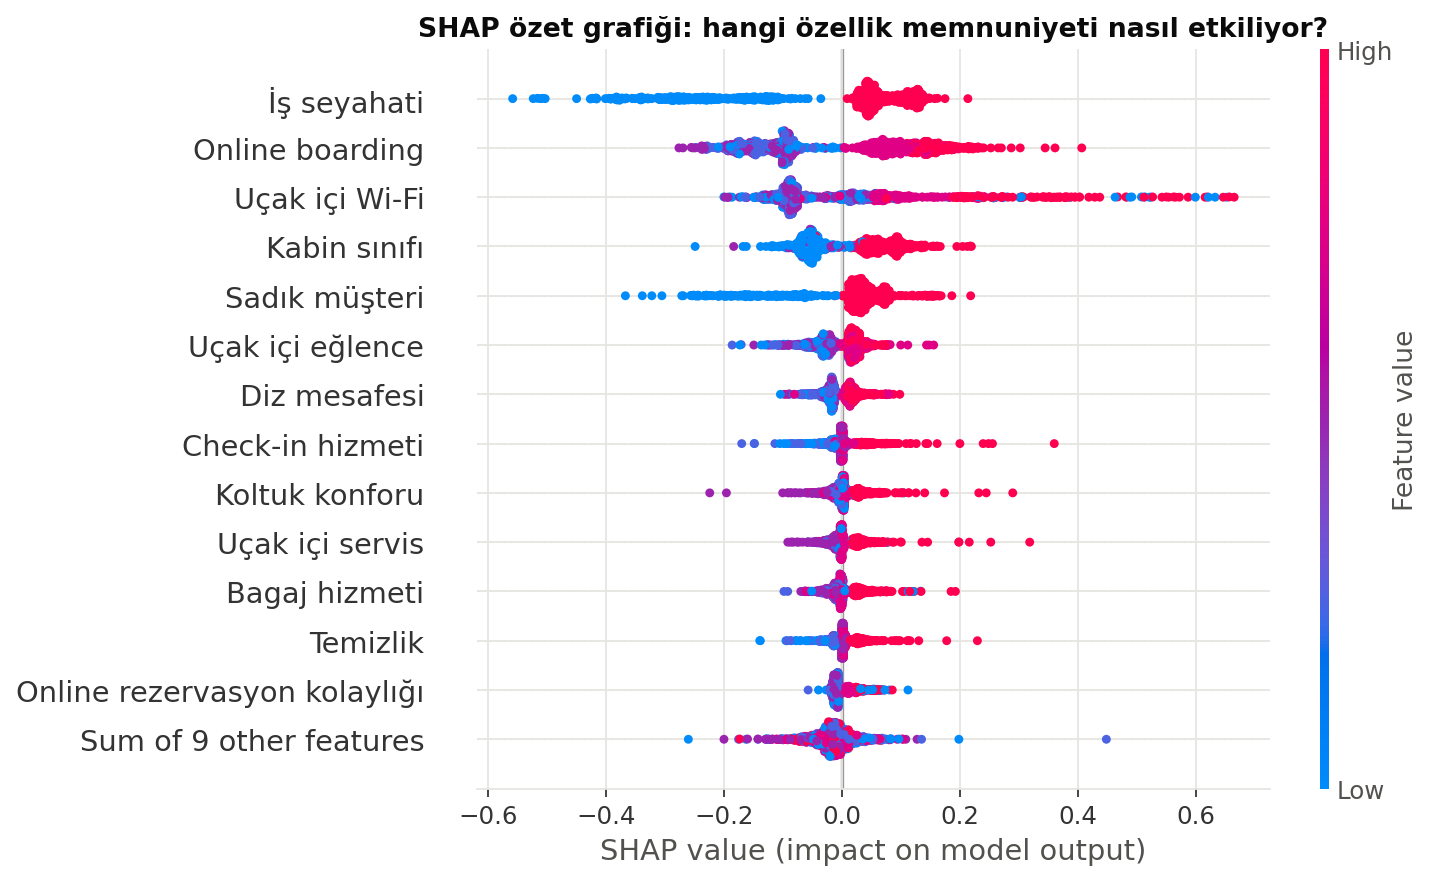

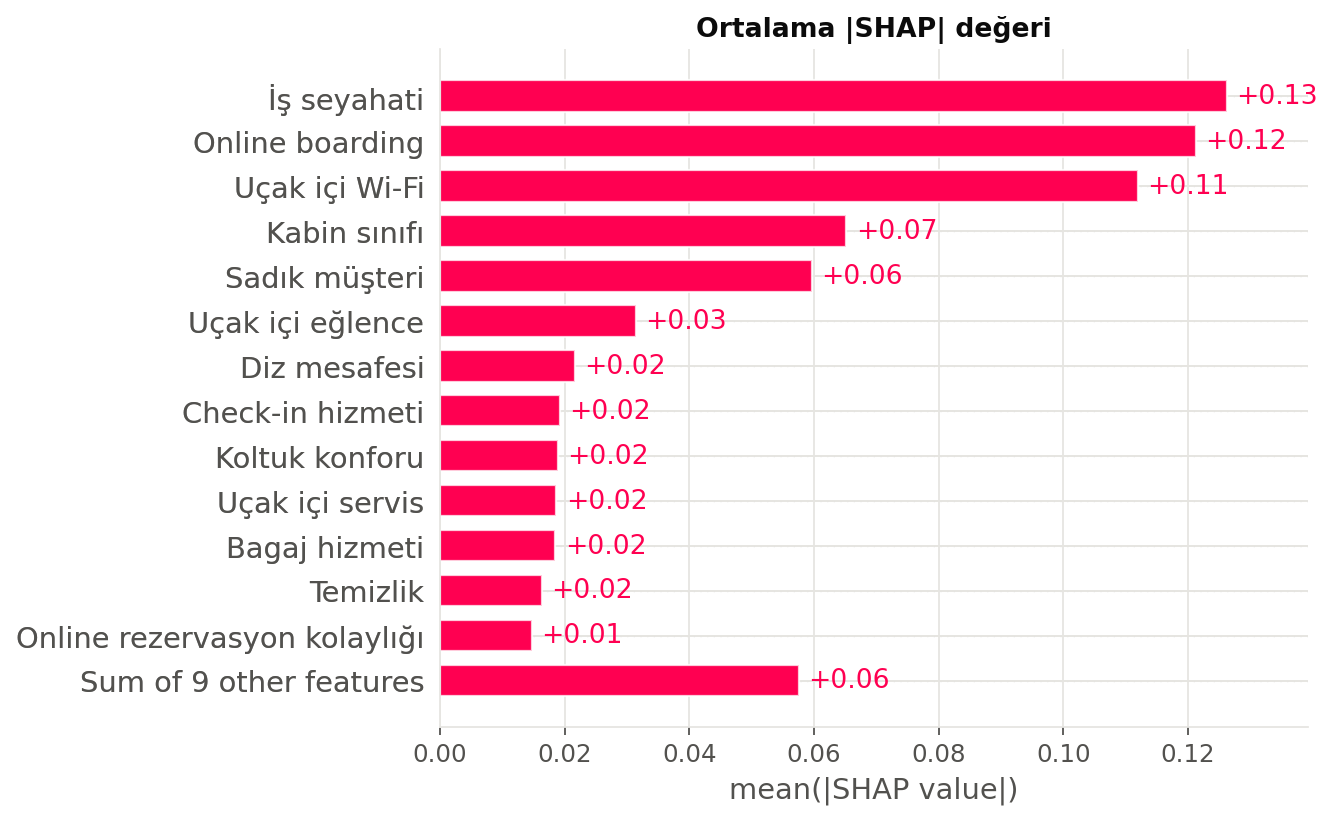

,feature,mean_abs_shap
0,İş seyahati,0.126318
1,Online boarding,0.121340
2,Uçak içi Wi-Fi,0.111997
3,Kabin sınıfı,0.065212
4,Sadık müşteri,0.059687
5,Uçak içi eğlence,0.031401
6,Diz mesafesi,0.021617
7,Check-in hizmeti,0.019310
8,Koltuk konforu,0.018878
9,Uçak içi servis,0.018699


In [4]:
sv, Xs = ex.shap_values(rf, X_test)
ex.plot_shap_summary(sv)
display(Image(C.FIG_DIR / "13_shap_beeswarm.png"), Image(C.FIG_DIR / "14_shap_bar.png"))
ex.shap_ranking(sv).head(10)

## 3. Segment analizi
Business ve Economy yolcusunu memnun eden şeyler aynı mı?

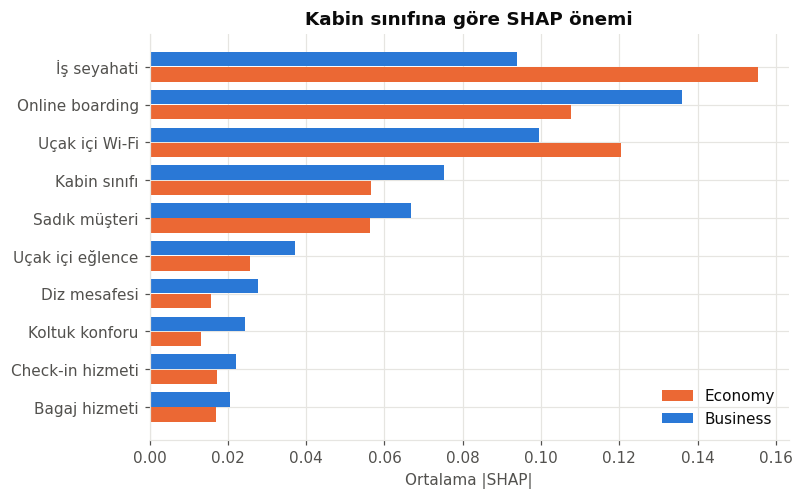

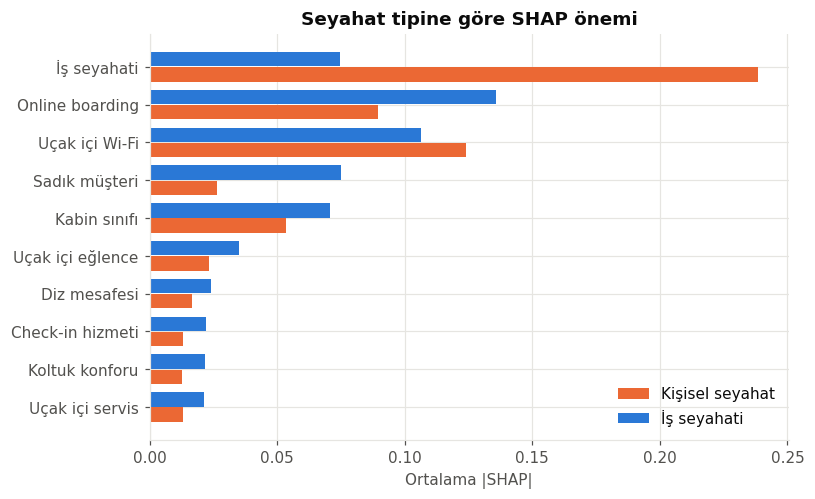

In [5]:
seg = ex.segment_shap(sv, Xs, "travel_class")
ex.plot_segment_shap(seg)
plt.show()
groups = {"Kişisel seyahat": Xs["type_of_travel"] == 0, "İş seyahati": Xs["type_of_travel"] == 1}
seg2 = ex.segment_shap(sv, Xs, "type_of_travel", groups)
ex.plot_segment_shap(seg2, title="Seyahat tipine göre SHAP önemi", name="15b_shap_seyahat_tipi")
plt.show()

## 4. Tek bir yolcunun açıklaması

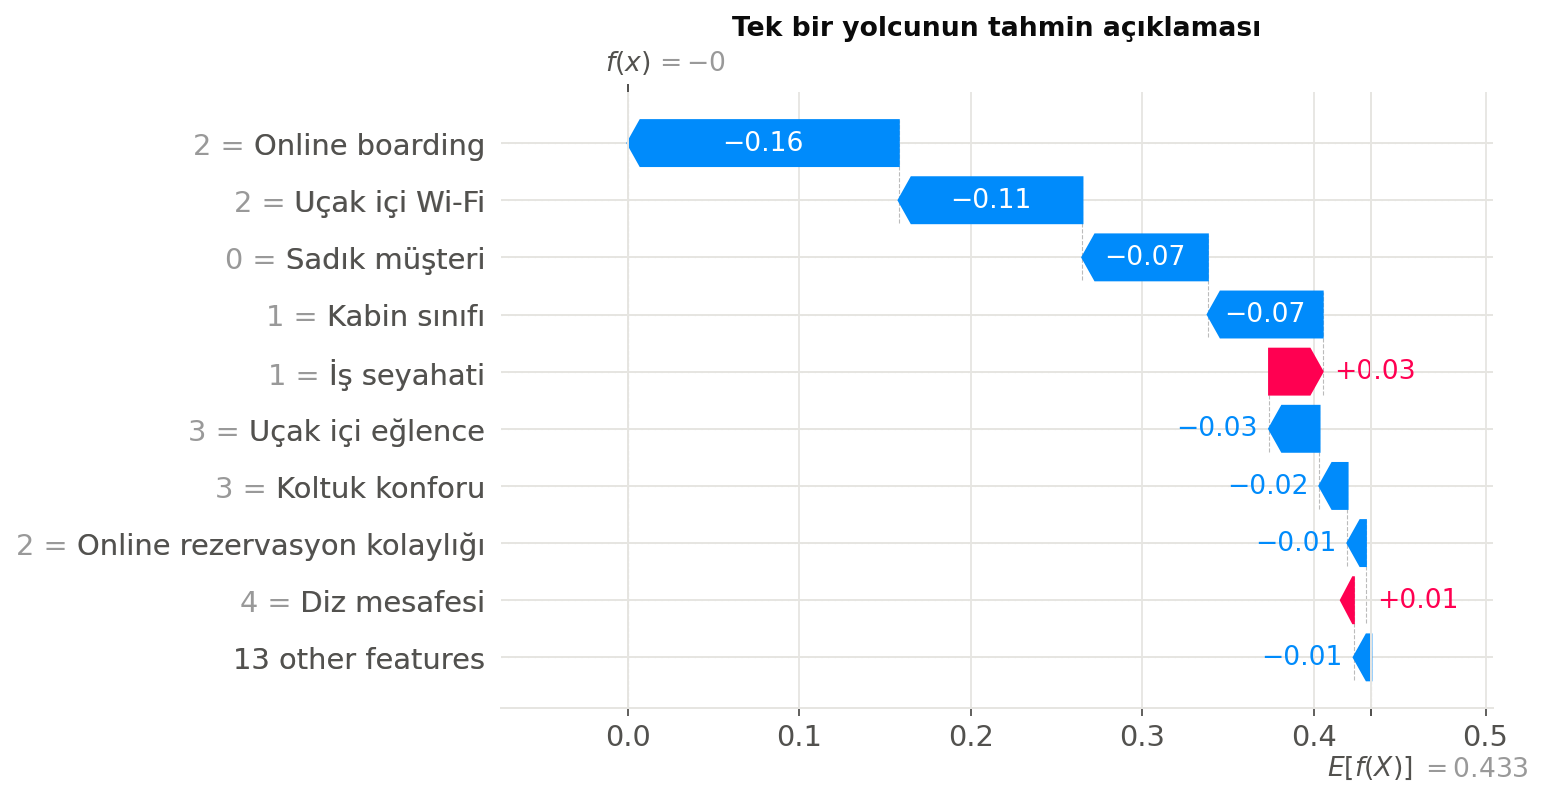

In [6]:
ex.plot_waterfall(sv, 0)
display(Image(C.FIG_DIR / "16_shap_tek_yolcu.png"))

## Yorum
- SHAP'e göre en belirleyici beş özellik: iş seyahati (ortalama |SHAP| 0,126), online boarding
  (0,121), Wi-Fi (0,112), kabin sınıfı (0,065) ve sadık müşteri (0,060). Hizmetler arasında ilk iki
  sırayı dijital hizmetler alıyor.
- Önem ölçüleri kısmen ayrışıyor: Gini önemi online boarding'i öne çıkarıyor (0,272), permutation
  önemi ise seyahat tipini (0,214) ve Wi-Fi'yi (0,183). İlişkili özellikler birbirinin yerini
  tutabildiği için tek bir ölçüye dayanmak yanıltıcı olabilir; üç ölçü birlikte okunmalı.
- Economy'de iş seyahati (0,156) ve Wi-Fi (0,120) ilk iki sırada; Business'ta online boarding
  (0,136) birinci, Wi-Fi (0,099) ikinci. Koltuk konforu (0,024 / 0,013), diz mesafesi
  (0,028 / 0,016) ve uçak içi eğlence (0,037 / 0,026) Business'ta Economy'ye göre daha ağırlıklı.
- Kişisel seyahatte seyahat tipi değişkeni baskın (0,239). İş seyahatinde online boarding (0,136)
  ve Wi-Fi (0,106) öne çıkıyor; müşteri sadakati de daha önemli (0,075 / 0,026).